
#FACULTY OF ENGINEERING, DESIGN AND TECHNOLOGY DEPARTMENT OF COMPUTING AND TECHNOLOGY ADVENT 2026 SEMESTER ASSIGNMENT ONE (25 Marks)
## PROGRAM: Master of Science in Data Science
# COURSE NAME: Data Science Lifecycle
#The objective of this assignment is to apply exploratory data analysis and statistical techniques to the automobile dataset in order to identify the key variables that influence car price
#You have been provided with the automobileEDA.csv dataset. Use it to find main variables/features that have the most impact on the car price. Questions:
#1. Explore the features in the dataset that could be used to predict the price of a car. Check for missing values, duplicates and outliers, and handle any you find. Save the cleaned dataset as YourLastName Data.csv. [5 Marks]
##2. Analyse patterns and run descriptive statistics on the dataset. Give summary statistics for the continuous variables and frequency counts for the categorical variables. Use graphs to show how price and the other variables are distributed, and summarize the findings on the patterns observed. [5 Marks]
#3. Group the data by identified parameters, such as drive-wheels and body-style. Find the average price for each group and present the results using visuals and statistics. Which groups have the highest and lowest prices? [5 Marks]
##4. Identify the effect of the independent attributes on price using visuals and statistics.
#a) Continuous variables vs. price [2 Marks] b) Categorical variables vs. price [2 Marks] c) Two categorical variables [1 Marks]
#5. Based on your findings, identify the main variables that have the most impact on car price, and support your answer with a feature selection method. Write a short recommendation for a car dealer setting prices. [5 Marks]
#Submission instructions: Submit a single zipped file named using the format Assignment1 YourLastName. This should have the cleaned dataset as well as executed notebook. Also, Submit a link to your GitHub or Kaggle account showing your Jupyter notebook. It must include your Python code and an explanation of every output. **bold text**












Question One
1. Explore the features in the dataset that could be used to predict the price of a car. Check for missing values, duplicates and outliers, and handle any you find. Save the cleaned dataset as YourLastName Data.csv. [5 Marks]

In [ ]:
from google.colab import files
uploaded = files.upload()
import pandas as pd
df = pd.read_csv("automobileEDA.csv")
df.head()

Saving automobileEDA.csv to automobileEDA.csv


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [ ]:
#Checking for missing values
#Step 1
#Load data
import pandas as pd
import numpy as np

df = pd.read_csv("automobileEDA.csv")
print("Shape:", df.shape)

Shape: (201, 29)


In [ ]:
#Count missing values in each column
missing = df.isna().sum()
print(missing)

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64


In [ ]:
#3. Show only columns that have missing values, with percentages
missing_table = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().sum() / len(df) * 100).round(2)
})
missing_table = missing_table[missing_table["missing_count"] > 0]
print(missing_table.sort_values("missing_count", ascending=False))

                   missing_count  missing_percent
stroke                         4             1.99
horsepower-binned              1             0.50


In [ ]:
#Total missing values and rows affected
print("Total missing cells:", df.isna().sum().sum())
print("Rows with at least one missing value:", df.isna().any(axis=1).sum())
#rows that have missing values
df[df.isna().any(axis=1)]

Total missing cells: 5
Rows with at least one missing value: 5


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
46,0,122,jaguar,std,two,sedan,rwd,front,102.0,0.921192,...,11.5,262.0,5000.0,13,17,36000.0,18.076923,NaN,0,1
52,3,150,mazda,std,two,hatchback,rwd,front,95.3,0.812110,...,9.4,101.0,6000.0,17,23,10945.0,13.823529,Low,0,1
53,3,150,mazda,std,two,hatchback,rwd,front,95.3,0.812110,...,9.4,101.0,6000.0,17,23,11845.0,13.823529,Low,0,1
54,3,150,mazda,std,two,hatchback,rwd,front,95.3,0.812110,...,9.4,101.0,6000.0,17,23,13645.0,13.823529,Low,0,1
55,3,150,mazda,std,two,hatchback,rwd,front,95.3,0.812110,...,9.4,135.0,6000.0,16,23,15645.0,14.687500,Medium,0,1


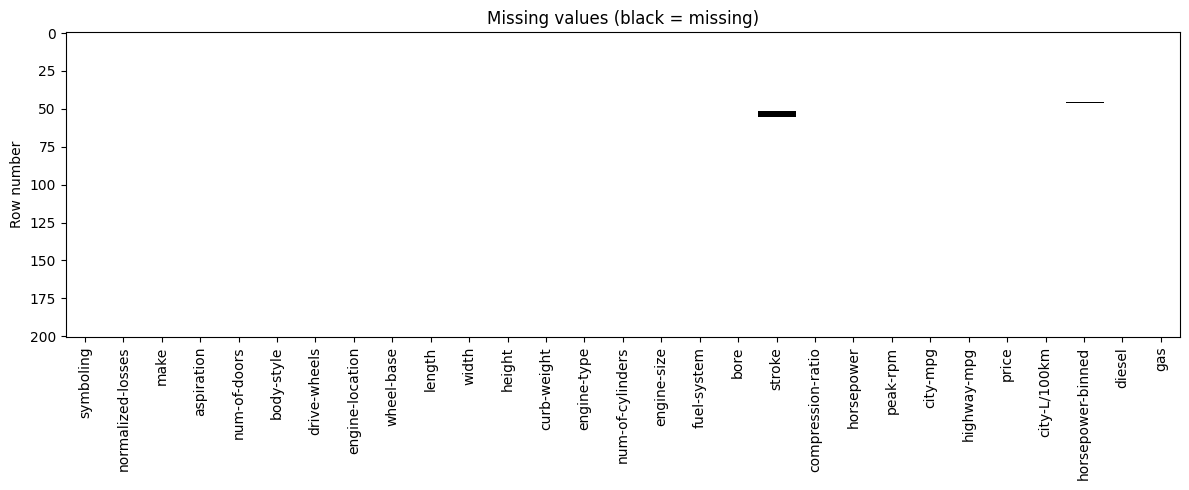

In [ ]:
# a picture of the missing values
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.imshow(df.isna(), aspect="auto", cmap="gray_r", interpolation="none")
plt.xticks(range(len(df.columns)), df.columns, rotation=90)
plt.ylabel("Row number")
plt.title("Missing values (black = missing)")
plt.tight_layout()
plt.show()

In [ ]:
#Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


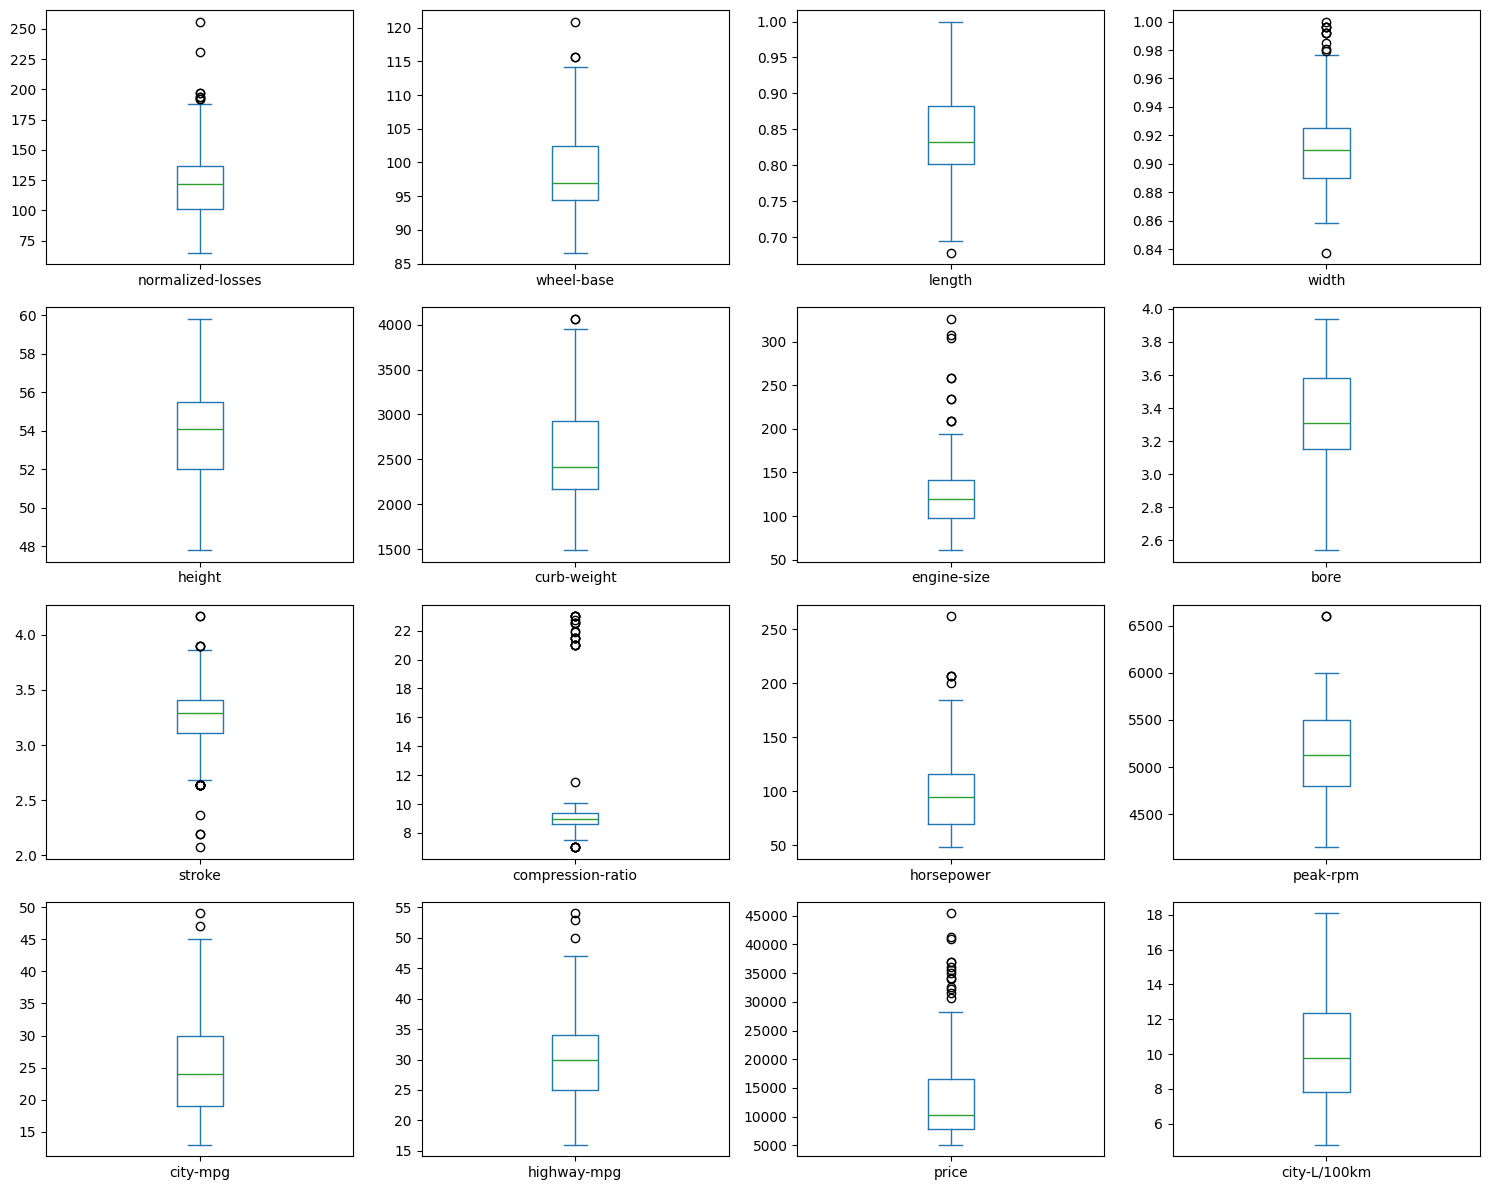

In [ ]:
#Load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("automobileEDA.csv")

# only continuous columns (skip 0/1 and rating columns)
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in ("diesel", "gas", "symboling", "price_outlier")]



#Method 1: Box plot (visual)

#Points outside the whiskers are possible outliers.
df[num_cols].plot(kind="box", subplots=True, layout=(4, 4), figsize=(15, 12))
plt.tight_layout()
plt.show()

In [ ]:
#Clean, Cell 2: Trim spaces, make text lower case, fix brand names
# remove extra spaces in all text columns
import pandas as pd
import numpy as np

df = pd.read_csv("automobileEDA.csv")
clean = df.copy()          # work on a copy, so the original stays safe
print("Shape:", clean.shape)

for col in clean.select_dtypes(exclude="number").columns:
    clean[col] = clean[col].str.strip()

# make the brand names lower case
clean["make"] = clean["make"].str.lower()

# fix the spelling mistakes
clean["make"] = clean["make"].replace({
    "peugot": "peugeot",
    "alfa-romero": "alfa-romeo"
})

print(sorted(clean["make"].unique()))   # check the brand names

Shape: (201, 29)
['alfa-romeo', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercedes-benz', 'mercury', 'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']


In [ ]:
# Cell 3: Fill the 4 missing stroke values with the median
print("Missing before:", clean["stroke"].isna().sum())     # 4

clean["stroke"] = clean["stroke"].fillna(clean["stroke"].median())

print("Missing after:", clean["stroke"].isna().sum())      # 0

Missing before: 4
Missing after: 0


In [ ]:
#Cell 4: Fill the missing horsepower-binned (the Jaguar with 262 hp)
print("Missing before:", clean["horsepower-binned"].isna().sum())   # 1

def hp_bin(hp):
    if hp <= 101:
        return "Low"
    elif hp <= 155:
        return "Medium"
    else:
        return "High"          # 262 hp goes here

clean["horsepower-binned"] = clean["horsepower-binned"].fillna(clean["horsepower"].apply(hp_bin))

print("Missing after:", clean["horsepower-binned"].isna().sum())    # 0

Missing before: 1
Missing after: 0


In [ ]:
#Cell 5: Round peak-rpm and change to whole-number types
clean["peak-rpm"]   = clean["peak-rpm"].round(0).astype(int)
clean["horsepower"] = clean["horsepower"].astype(int)
clean["price"]      = clean["price"].astype(int)

print(clean[["peak-rpm", "horsepower", "price"]].dtypes)

peak-rpm      int64
horsepower    int64
price         int64
dtype: object


In [ ]:
#Cell 6: Round the long decimals
for col in ["length", "width", "city-L/100km", "bore", "stroke"]:
    clean[col] = clean[col].round(3)

In [ ]:
# Final check
print("Shape:", clean.shape)                                  # (201, 30)
print("Missing values:", clean.isna().sum().sum())            # 0
print("Duplicate rows:", clean.duplicated().sum())            # 0
clean.info()

Shape: (201, 29)
Missing values: 0
Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    object 
 3   aspiration         201 non-null    object 
 4   num-of-doors       201 non-null    object 
 5   body-style         201 non-null    object 
 6   drive-wheels       201 non-null    object 
 7   engine-location    201 non-null    object 
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    object 
 14  num-of-cylinders   201 non-null    object 
 15  engine-size        20

In [ ]:
#Cell 9: Save and download
clean.to_csv("Okoch.csv", index=False)

from google.colab import files
files.download("Okoch.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Load the cleaned data
import pandas as pd
import numpy as np

clean = pd.read_csv("Okoch.csv")
print(clean.shape)    # (201, 29)

(201, 29)


In [ ]:
#Choose the continuous and categorical variables
continuous = ["normalized-losses", "wheel-base", "length", "width", "height",
              "curb-weight", "engine-size", "bore", "stroke", "compression-ratio",
              "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price", "city-L/100km"]

categorical = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels",
               "engine-location", "engine-type", "num-of-cylinders", "fuel-system",
               "horsepower-binned", "symboling", "diesel", "gas"]
#symboling (risk rating), diesel and gas are numbers, but they are categories, so I put them in the categorical list. The column price_outlier is a flag, so I left it out.

In [ ]:
#Summary statistics for the continuous variables
clean[continuous].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
normalized-losses,201.0,122.00,32.00,65.00,101.00,122.00,137.00,256.00
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00


In [ ]:
for col in categorical:
    table = pd.DataFrame({
        "count": clean[col].value_counts(),
        "percent": clean[col].value_counts(normalize=True).mul(100).round(1)
    })
    print(f"\n=== {col} ===")
    print(table)


=== make ===
               count  percent
make                         
toyota            32     15.9
nissan            18      9.0
mazda             17      8.5
mitsubishi        13      6.5
honda             13      6.5
subaru            12      6.0
volkswagen        12      6.0
volvo             11      5.5
peugeot           11      5.5
dodge              9      4.5
mercedes-benz      8      4.0
bmw                8      4.0
plymouth           7      3.5
audi               6      3.0
saab               6      3.0
porsche            4      2.0
chevrolet          3      1.5
alfa-romeo         3      1.5
jaguar             3      1.5
isuzu              2      1.0
renault            2      1.0
mercury            1      0.5

=== aspiration ===
            count  percent
aspiration                
std           165     82.1
turbo          36     17.9

=== num-of-doors ===
              count  percent
num-of-doors                
four            115     57.2
two              86     42.8


In [ ]:
#Frequency counts for the categorical variables
counts = clean["body-style"].value_counts()
percent = clean["body-style"].value_counts(normalize=True).mul(100).round(1)

pd.DataFrame({"count": counts, "percent": percent})

,count,percent
body-style,,
sedan,94,46.8
hatchback,68,33.8
wagon,25,12.4
hardtop,8,4.0
convertible,6,3.0


In [ ]:
#one table
freq_list = []
for col in categorical:
    t = pd.DataFrame({
        "variable": col,
        "category": clean[col].value_counts().index.astype(str),
        "count": clean[col].value_counts().values,
        "percent": clean[col].value_counts(normalize=True).mul(100).round(1).values
    })
    freq_list.append(t)

freq_table = pd.concat(freq_list, ignore_index=True)
freq_table

,variable,category,count,percent
0,make,toyota,32,15.9
1,make,nissan,18,9.0
2,make,mazda,17,8.5
3,make,mitsubishi,13,6.5
4,make,honda,13,6.5
...,...,...,...,...
65,symboling,-2,3,1.5
66,diesel,0,181,90.0
67,diesel,1,20,10.0
68,gas,1,181,90.0


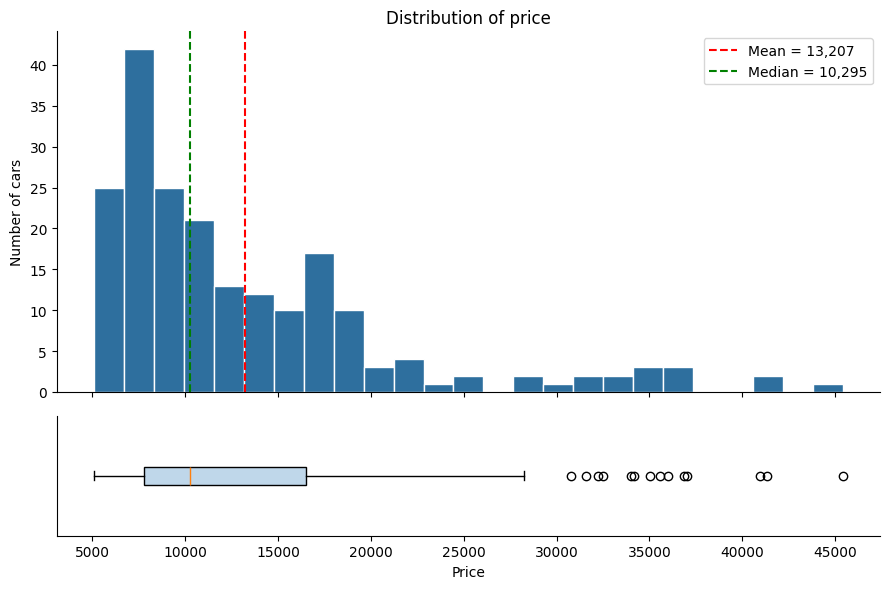

In [ ]:
#Load the data and set up
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Okoch.csv")
df["fuel"] = np.where(df["diesel"] == 1, "diesel", "gas")   # one fuel column for graphs

plt.rcParams.update({"font.size": 10,
                     "axes.spines.top": False,
                     "axes.spines.right": False})
BLUE = "#2E6F9E"




#Graph 1: Distribution of price (histogram and box plot)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]})

ax[0].hist(df["price"], bins=25, color=BLUE, edgecolor="white")
ax[0].axvline(df["price"].mean(), color="red", ls="--", label=f"Mean = {df['price'].mean():,.0f}")
ax[0].axvline(df["price"].median(), color="green", ls="--", label=f"Median = {df['price'].median():,.0f}")
ax[0].set_title("Distribution of price")
ax[0].set_ylabel("Number of cars")
ax[0].legend()

ax[1].boxplot(df["price"], vert=False, patch_artist=True,
              boxprops=dict(facecolor="#BFD7EA"))
ax[1].set_xlabel("Price")
ax[1].set_yticks([])

plt.tight_layout()
plt.show()

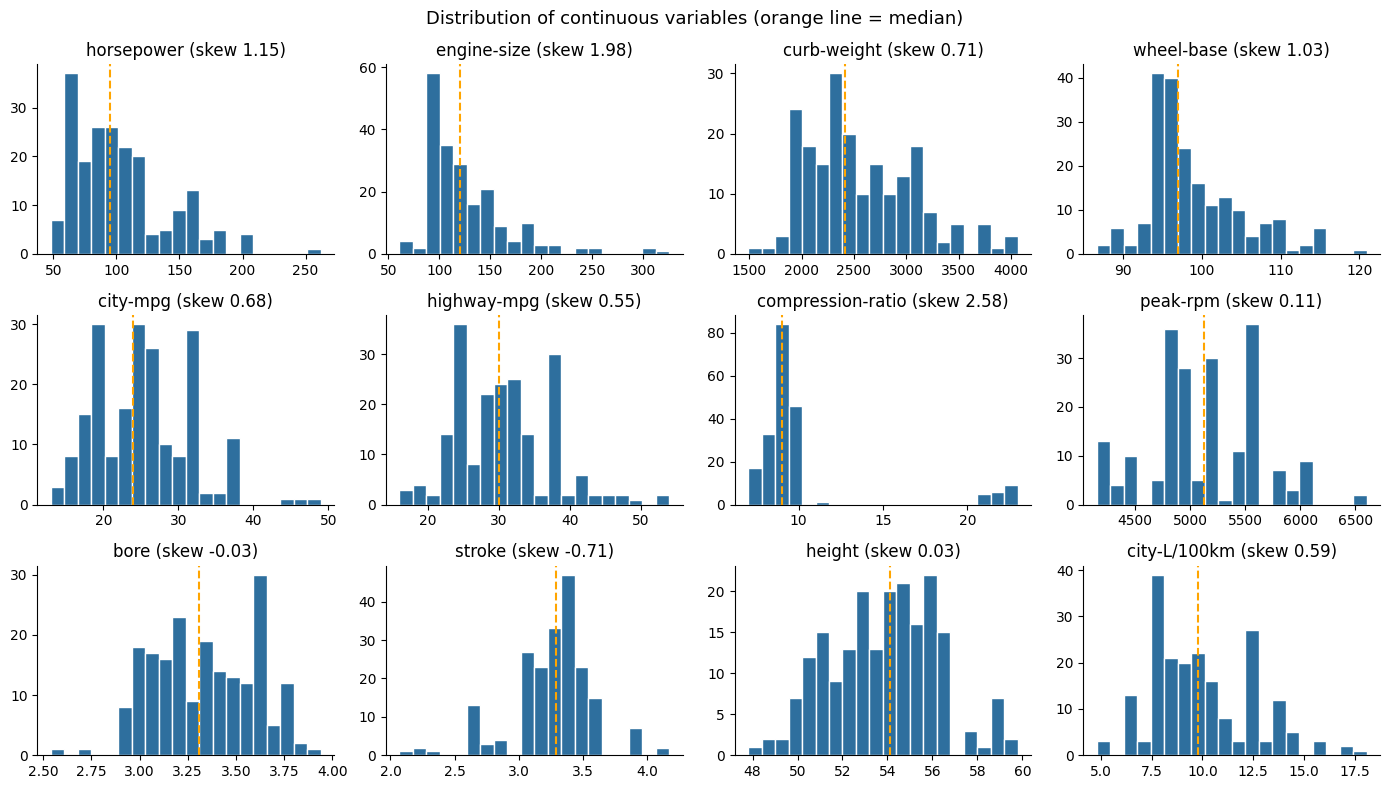

In [ ]:
# Graph 2: Histograms of the other continuous variables
vars_ = ["horsepower", "engine-size", "curb-weight", "wheel-base",
         "city-mpg", "highway-mpg", "compression-ratio", "peak-rpm",
         "bore", "stroke", "height", "city-L/100km"]

fig, axs = plt.subplots(3, 4, figsize=(14, 8))
for ax, v in zip(axs.ravel(), vars_):
    ax.hist(df[v], bins=20, color=BLUE, edgecolor="white")
    ax.axvline(df[v].median(), color="orange", ls="--")
    ax.set_title(f"{v} (skew {df[v].skew():.2f})")

fig.suptitle("Distribution of continuous variables (orange line = median)", fontsize=13)
plt.tight_layout()
plt.show()

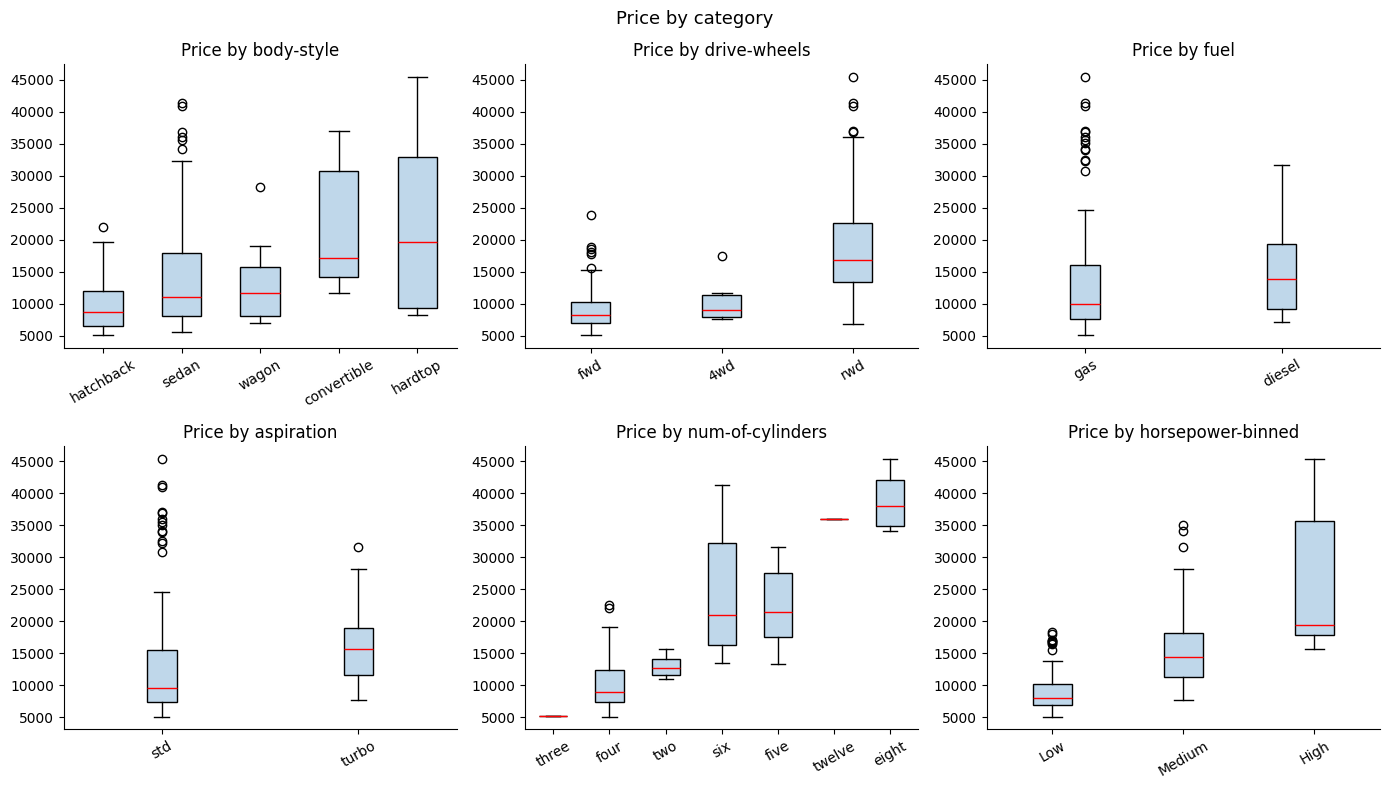

In [ ]:
#Graph 3: Price by category (box plots)
cats = ["body-style", "drive-wheels", "fuel", "aspiration",
        "num-of-cylinders", "horsepower-binned"]

fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axs.ravel(), cats):
    order = df.groupby(c)["price"].median().sort_values().index
    ax.boxplot([df.loc[df[c] == k, "price"] for k in order],
               tick_labels=order, patch_artist=True,
               boxprops=dict(facecolor="#BFD7EA"),
               medianprops=dict(color="red"))
    ax.set_title(f"Price by {c}")
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Price by category", fontsize=13)
plt.tight_layout()
plt.show()

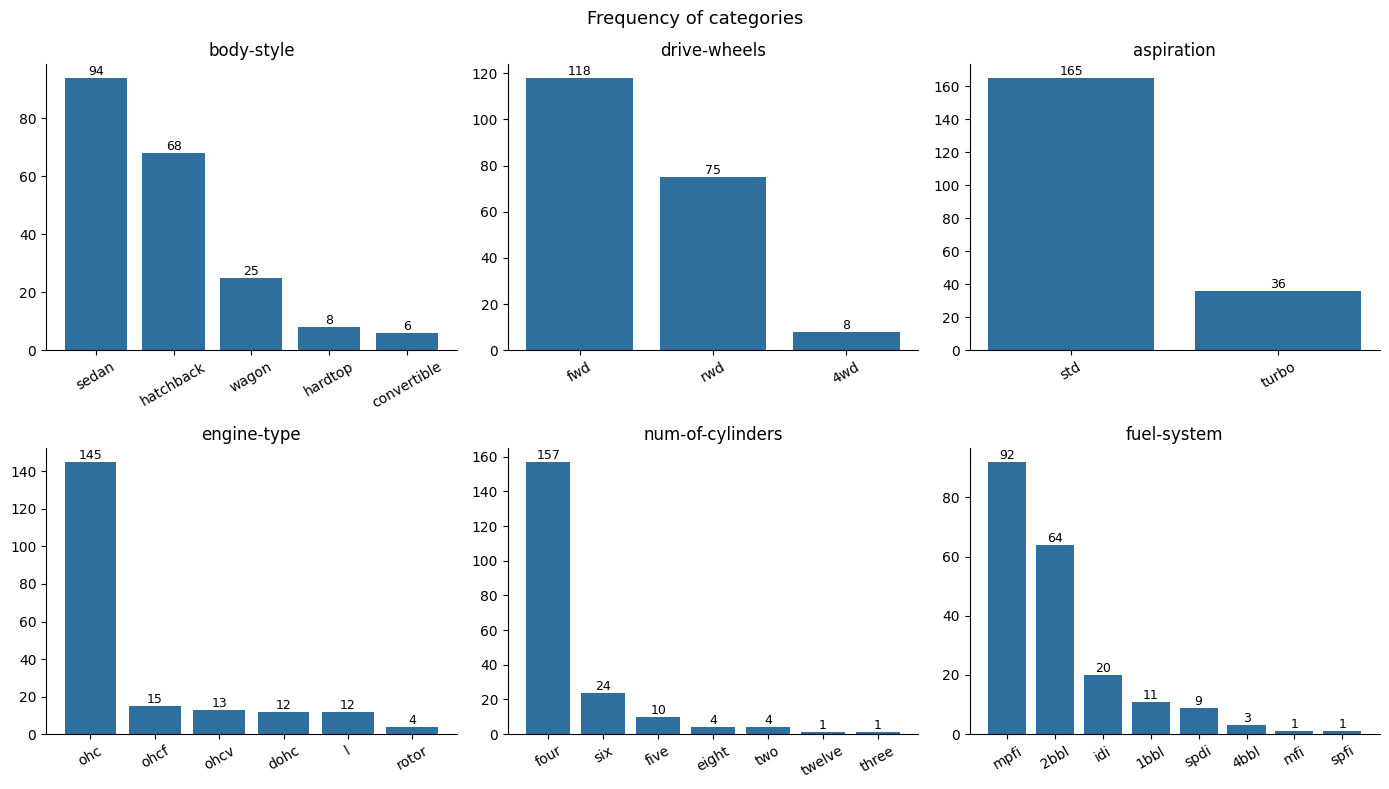

In [ ]:
#Graph 4: Frequency of categories (bar charts)
cats2 = ["body-style", "drive-wheels", "aspiration",
         "engine-type", "num-of-cylinders", "fuel-system"]

fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axs.ravel(), cats2):
    vc = df[c].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=BLUE)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Frequency of categories", fontsize=13)
plt.tight_layout()
plt.show()

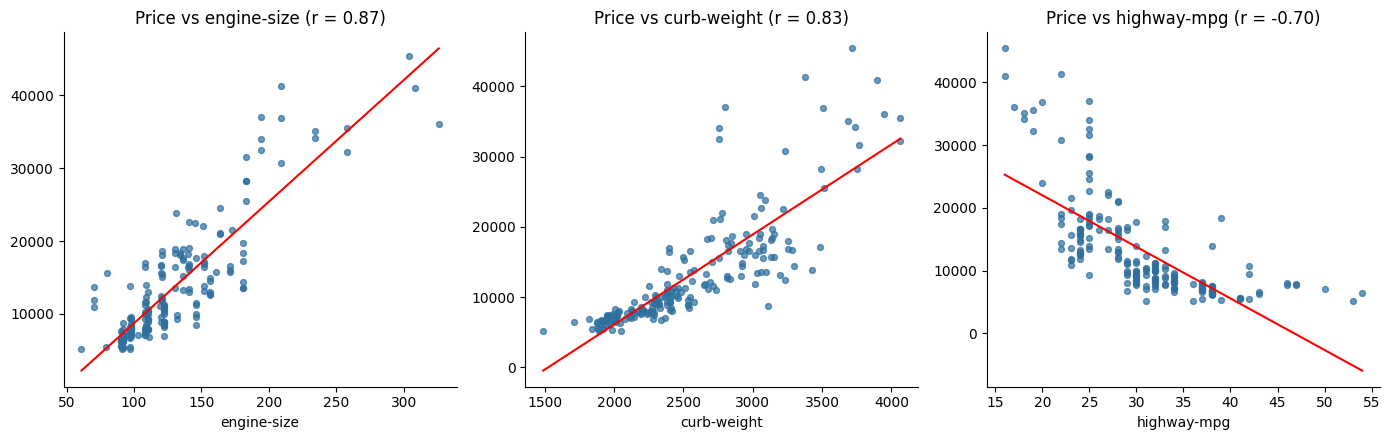

In [ ]:
# Graph 6: Price against key variables (scatter plots)
fig, axs = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, v in zip(axs, ["engine-size", "curb-weight", "highway-mpg"]):
    ax.scatter(df[v], df["price"], s=18, alpha=0.7, color=BLUE)
    slope, intercept = np.polyfit(df[v], df["price"], 1)
    xs = np.linspace(df[v].min(), df[v].max(), 50)
    ax.plot(xs, slope * xs + intercept, color="red")
    ax.set_title(f"Price vs {v} (r = {df[v].corr(df['price']):.2f})")
    ax.set_xlabel(v)

plt.tight_layout()
plt.show()

# Explaination
**Summary of the patterns in the graphs**

Graph 1: Price distribution

The histogram has a long tail on the right. Most cars are cheap, and few are expensive.
The mean (13,207) is to the right of the median (10,295).
The box plot shows 14 outliers above about 30,000, up to 45,400.

Graph 2: Other continuous variables

Right-skewed: engine-size, compression-ratio, horsepower and wheel-base. A few big or powerful cars stretch the right side.
Fairly balanced: height, bore, stroke and peak-rpm.
Two groups in compression-ratio: petrol cars sit near 9, and diesel cars sit near 21 to 23.
City-mpg and highway-mpg are mostly in the 20s and 30s. A few very efficient cars reach 49 and 54.

Graph 3: Price by category

Rear-wheel drive cars sit much higher than front-wheel drive and 4wd cars.
Hardtop and convertible cars have the highest middle prices. Hatchbacks are lowest.
Turbo cars and diesel cars have higher middle prices than standard cars and gas cars.
Price rises step by step as cylinders go up and as horsepower goes from Low to Medium to High.
Almost all the outliers are gas, standard, rear-wheel drive cars, mostly sedans.

Graph 4: Category counts

Most cars are sedans or hatchbacks, front-wheel drive, standard aspiration and four-cylinder.
The ohc engine type and the mpfi and 2bbl fuel systems dominate.
Some categories have very few cars (rotor, mfi, spfi, 3 and 12 cylinders).

Graph 5: Make

Toyota has the most cars (32). Mercury has only 1.
Jaguar, Mercedes-Benz and Porsche have the highest average prices. Chevrolet, Dodge and Plymouth have the lowest.

Graph 6: Price against key variables

Price rises as engine-size (r = 0.87) and curb-weight (r = 0.83) rise.
Price falls as highway-mpg rises (r = -0.70).
The points spread out more at higher values, so prices vary more for big engines than for small ones.
Main message

Cheap, small, fuel-efficient cars are the majority. A smaller group of large, powerful, rear-wheel drive cars from luxury brands is much more expensive. These cars cause the long right tail in price. Because price is skewed, use the median to describe a “typical” price.

Question 3

In [ ]:
df = pd.read_csv("Okoch.csv")
plt.rcParams.update({"font.size": 10,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

In [ ]:
# Group by one parameter and find the average price
# by drive-wheels
by_drive = df.groupby("drive-wheels")["price"].mean().round(0)
print(by_drive.sort_values(ascending=False))

# by body-style
by_body = df.groupby("body-style")["price"].mean().round(0)
print(by_body.sort_values(ascending=False))

drive-wheels
rwd    19758.0
4wd    10241.0
fwd     9245.0
Name: price, dtype: float64
body-style
hardtop        22208.0
convertible    21890.0
sedan          14460.0
wagon          12372.0
hatchback       9957.0
Name: price, dtype: float64


In [ ]:
#Full statistics for each group

# Do not look at the mean alone. Add the number of cars (count), the median and the spread.
def group_stats(by):
    g = df.groupby(by)["price"].agg(
        count="count", mean="mean", median="median",
        std="std", min="min", max="max")
    return g.round(0).sort_values("mean", ascending=False)

drive_stats = group_stats("drive-wheels")
body_stats  = group_stats("body-style")

print(drive_stats)
print(body_stats)

              count     mean   median     std   min    max
drive-wheels                                              
rwd              75  19758.0  16900.0  9083.0  6785  45400
4wd               8  10241.0   9006.0  3288.0  7603  17450
fwd             118   9245.0   8192.0  3346.0  5118  23875
             count     mean   median      std    min    max
body-style                                                 
hardtop          8  22208.0  19688.0  14556.0   8249  45400
convertible      6  21890.0  17084.0  11188.0  11595  37028
sedan           94  14460.0  11078.0   8523.0   5499  41315
wagon           25  12372.0  11694.0   5121.0   6918  28248
hatchback       68   9957.0   8672.0   4149.0   5118  22018


In [ ]:
#Group by both parameters together
pivot_mean  = df.pivot_table(index="drive-wheels", columns="body-style",
                             values="price", aggfunc="mean").round(0)
pivot_count = df.pivot_table(index="drive-wheels", columns="body-style",
                             values="price", aggfunc="count").fillna(0).astype(int)

print(pivot_mean)
print(pivot_count)

body-style    convertible  hardtop  hatchback    sedan    wagon
drive-wheels                                                   
4wd                   NaN      NaN     7603.0  12647.0   9096.0
fwd               11595.0   8249.0     8396.0   9812.0   9997.0
rwd               23950.0  24203.0    14338.0  21712.0  16994.0
body-style    convertible  hardtop  hatchback  sedan  wagon
drive-wheels                                               
4wd                     0        0          1      3      4
fwd                     1        1         49     55     12
rwd                     5        7         18     36      9


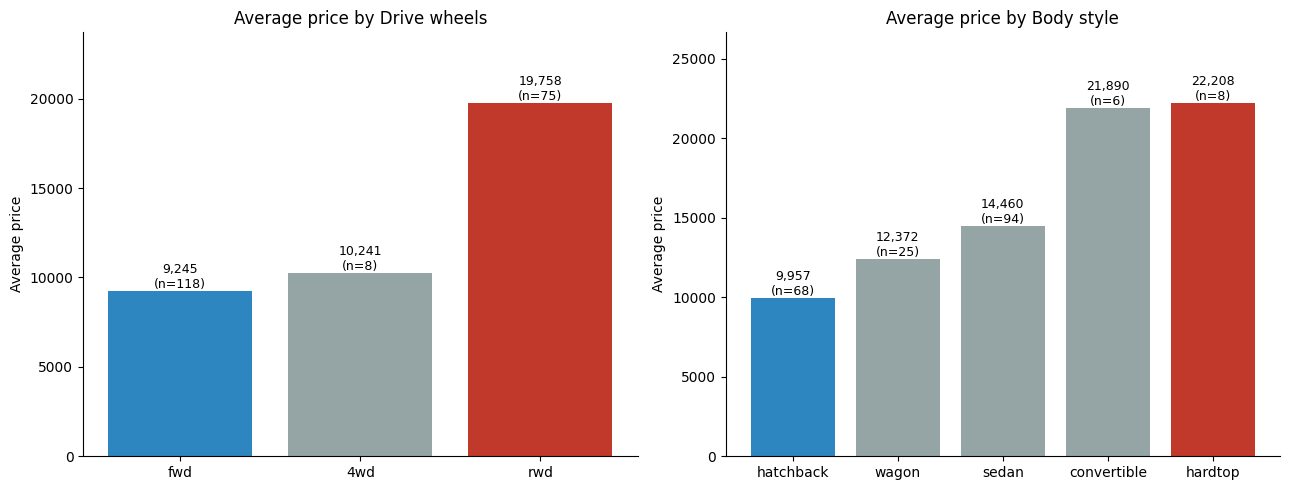

In [ ]:
#Bar charts of average price (red = highest, blue = lowest)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for a, t, title in [(ax[0], drive_stats, "Drive wheels"),
                    (ax[1], body_stats, "Body style")]:
    t = t.sort_values("mean")
    colors = ["#C0392B" if m == t["mean"].max()
              else "#2E86C1" if m == t["mean"].min()
              else "#95A5A6" for m in t["mean"]]
    a.bar(t.index, t["mean"], color=colors)
    for i, (m, n) in enumerate(zip(t["mean"], t["count"])):
        a.text(i, m, f"{m:,.0f}\n(n={n})", ha="center", va="bottom", fontsize=9)
    a.set_title(f"Average price by {title}")
    a.set_ylabel("Average price")
    a.set_ylim(0, t["mean"].max() * 1.2)

plt.tight_layout()
plt.show()

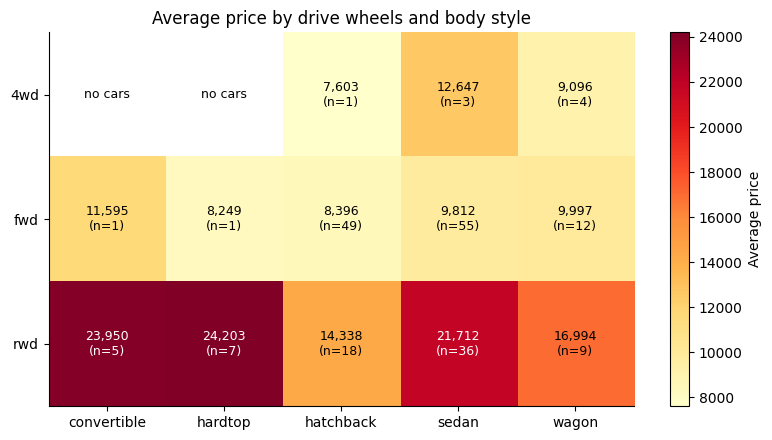

In [ ]:
#Heatmap of both parameters together
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(pivot_mean.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(pivot_mean.columns)), pivot_mean.columns)
ax.set_yticks(range(len(pivot_mean.index)), pivot_mean.index)

for i in range(pivot_mean.shape[0]):
    for j in range(pivot_mean.shape[1]):
        v = pivot_mean.values[i, j]
        text = "no cars" if np.isnan(v) else f"{v:,.0f}\n(n={pivot_count.values[i, j]})"
        color = "white" if (not np.isnan(v) and v > 18000) else "black"
        ax.text(j, i, text, ha="center", va="center", fontsize=9, color=color)

plt.colorbar(im, label="Average price")
ax.set_title("Average price by drive wheels and body style")
plt.tight_layout()
plt.show()

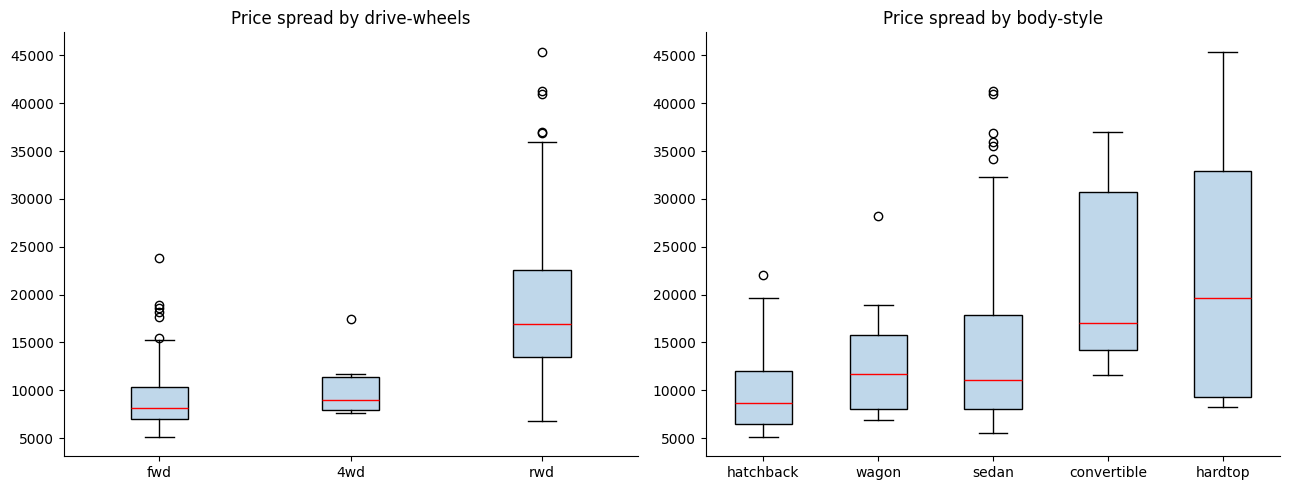

In [ ]:
#Box plots to see the spread inside each group
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, c in zip(ax, ["drive-wheels", "body-style"]):
    order = df.groupby(c)["price"].mean().sort_values().index
    a.boxplot([df.loc[df[c] == k, "price"] for k in order],
              tick_labels=order, patch_artist=True,
              boxprops=dict(facecolor="#BFD7EA"),
              medianprops=dict(color="red"))
    a.set_title(f"Price spread by {c}")

plt.tight_layout()
plt.show()

Explaination
Which groups are highest and lowest?

Drive wheels: Highest is rwd (19,758). Lowest is fwd (9,245).
Body style: Highest is hardtop (22,208), and convertible is very close. Lowest is hatchback (9,957).
Both together: Highest is rwd hardtop (24,203). Lowest is 4wd hatchback (7,603), but it has only 1 car. Among groups with 5 or more cars, the lowest is fwd hatchback (8,396).
What the graphs show
Bar charts: The gap is biggest for drive wheels. Rear-wheel drive cars cost more than twice as much as front-wheel drive cars.
Heatmap: The whole rwd row is darker than the fwd and 4wd rows. Price depends more on drive wheels than on body style. A fwd car is cheap for every body style (8,249 to 11,595).
Box plots: Hardtop, convertible and rwd have wide price ranges. Fwd and hatchback prices are tightly packed.

Q4. 4. Identify the effect of the independent attributes on price using visuals and statistics.
a) Continuous variables vs. price  
b) Categorical variables vs. price  
c) Two categorical variables

In [ ]:
#Load the data and set up
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("Okoch.csv")
df["fuel"] = np.where(df["diesel"] == 1, "diesel", "gas")   # one fuel column

plt.rcParams.update({"font.size": 10,
                     "axes.spines.top": False,
                     "axes.spines.right": False})
BLUE = "#2E6F9E"

In [ ]:
#Continuous variables vs price
#The tool here is correlation (r) and simple regression (R²). Correlation shows how strong and in which direction the link is. R² shows how much of the price variation the variable explains.
cont = ["engine-size", "curb-weight", "horsepower", "city-L/100km", "width",
        "length", "wheel-base", "bore", "height", "normalized-losses",
        "stroke", "compression-ratio", "peak-rpm", "city-mpg", "highway-mpg"]

rows = []
for v in cont:
    r, p = stats.pearsonr(df[v], df["price"])            # Pearson: straight-line link
    rho, ps = stats.spearmanr(df[v], df["price"])        # Spearman: works with skew and outliers
    rows.append([v, r, p, rho, r**2])

A = pd.DataFrame(rows, columns=["variable", "pearson_r", "p_value", "spearman_rho", "R2"])
A["strength"] = pd.cut(A["pearson_r"].abs(), [0, .3, .5, .7, 1.01],
                       labels=["weak", "moderate", "strong", "very strong"])
A["significant (p<0.05)"] = np.where(A["p_value"] < 0.05, "yes", "no")
A = A.sort_values("pearson_r", key=abs, ascending=False).reset_index(drop=True)
A.round(3)

,variable,pearson_r,p_value,spearman_rho,R2,strength,significant (p<0.05)
0,engine-size,0.872,0.000,0.828,0.761,very strong,yes
1,curb-weight,0.834,0.000,0.914,0.696,very strong,yes
2,horsepower,0.810,0.000,0.849,0.655,very strong,yes
3,city-L/100km,0.790,0.000,0.831,0.624,very strong,yes
4,width,0.751,0.000,0.812,0.564,very strong,yes
5,highway-mpg,-0.705,0.000,-0.827,0.497,very strong,yes
6,length,0.691,0.000,0.810,0.477,strong,yes
7,city-mpg,-0.687,0.000,-0.831,0.471,strong,yes
8,wheel-base,0.585,0.000,0.682,0.342,strong,yes
9,bore,0.543,0.000,0.646,0.295,strong,yes


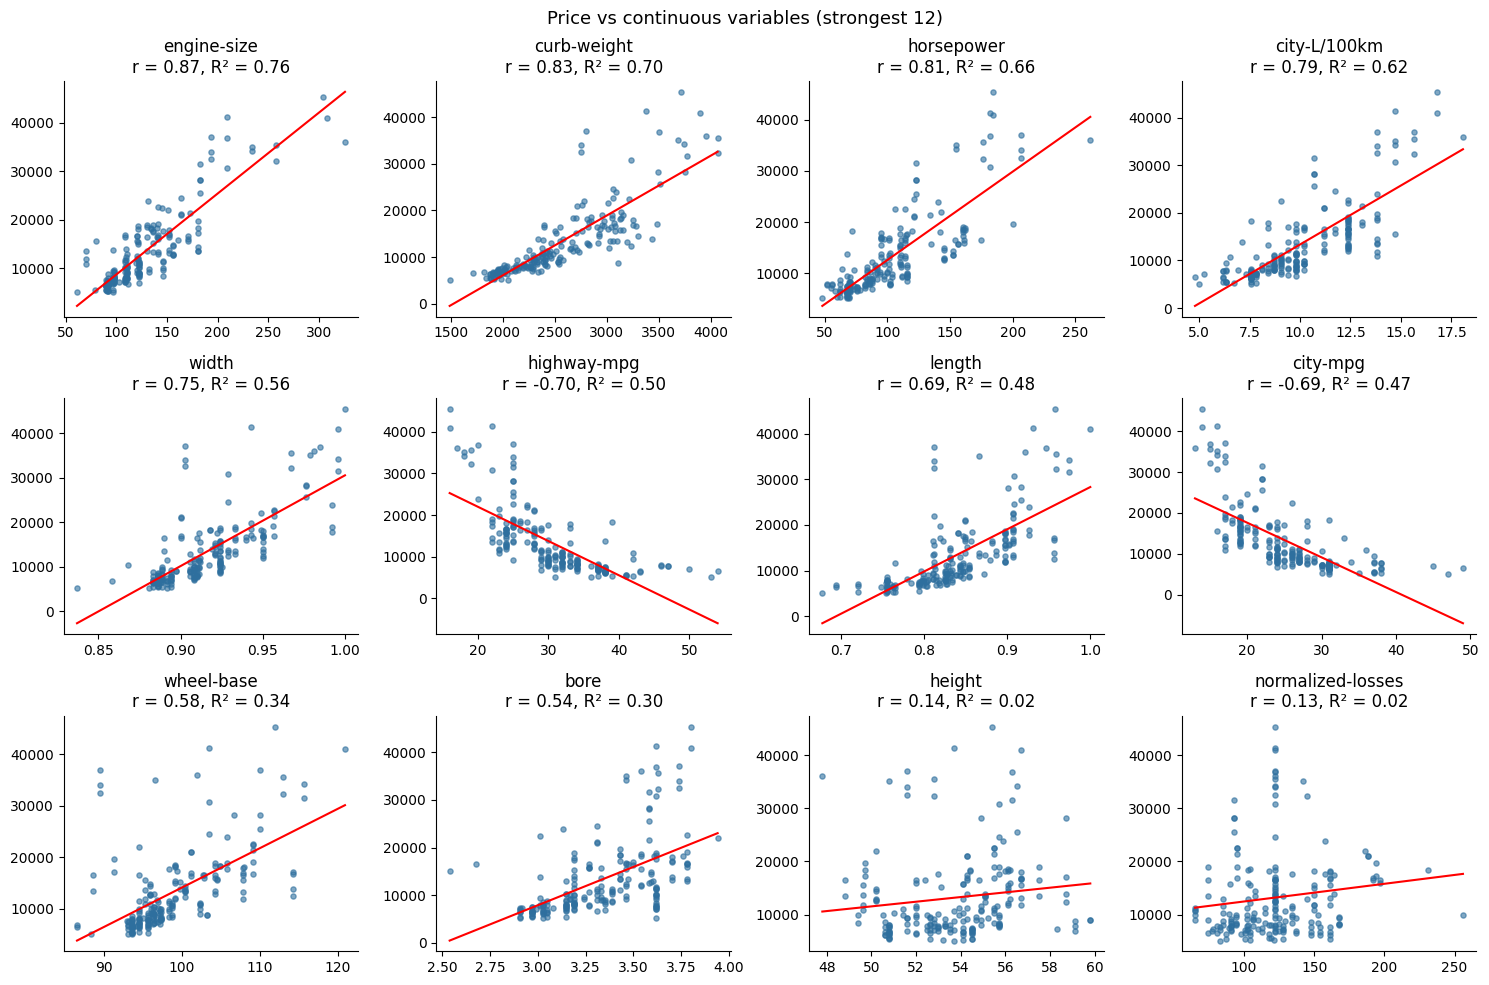

In [ ]:
# Scatter plots with a regression line
top12 = A["variable"].head(12).tolist()

fig, axs = plt.subplots(3, 4, figsize=(15, 10))
for ax, v in zip(axs.ravel(), top12):
    ax.scatter(df[v], df["price"], s=14, alpha=0.6, color=BLUE)
    slope, intercept = np.polyfit(df[v], df["price"], 1)
    xs = np.linspace(df[v].min(), df[v].max(), 50)
    ax.plot(xs, slope * xs + intercept, color="red")
    r = df[v].corr(df["price"])
    ax.set_title(f"{v}\nr = {r:.2f}, R² = {r**2:.2f}")

fig.suptitle("Price vs continuous variables (strongest 12)", fontsize=13)
plt.tight_layout()
plt.show()

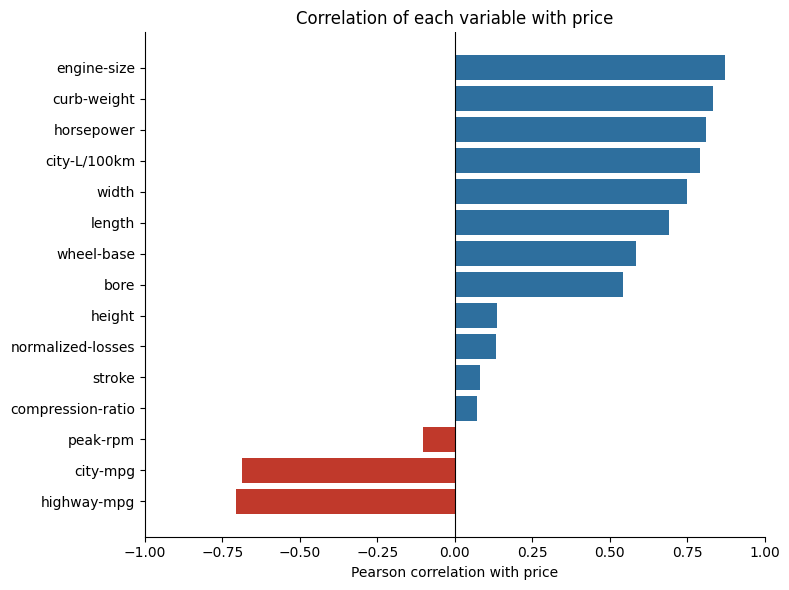

In [ ]:
#Bar chart of all correlations
B = A.sort_values("pearson_r")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(B["variable"], B["pearson_r"],
        color=["#C0392B" if r < 0 else BLUE for r in B["pearson_r"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Pearson correlation with price")
ax.set_title("Correlation of each variable with price")
plt.tight_layout()
plt.show()

In [ ]:
# Categorical variables vs price
#The tools are ANOVA (do the group means differ?), Kruskal-Wallis (the same idea, but safe for skewed data) and eta-squared (the share of price variation the variable explains).
cats = ["make", "num-of-cylinders", "horsepower-binned", "drive-wheels",
        "fuel-system", "engine-type", "body-style", "symboling",
        "engine-location", "aspiration", "fuel", "num-of-doors"]

rows = []
for c in cats:
    groups = [g["price"].values for _, g in df.groupby(c)]
    F, p = stats.f_oneway(*groups)
    H, pk = stats.kruskal(*groups)
    ss_between = sum(len(g) * (g.mean() - df["price"].mean())**2 for g in groups)
    ss_total = ((df["price"] - df["price"].mean())**2).sum()
    rows.append([c, len(groups), F, p, H, pk, ss_between / ss_total])

Bc = pd.DataFrame(rows, columns=["variable", "groups", "ANOVA_F", "ANOVA_p",
                                 "Kruskal_H", "Kruskal_p", "eta_squared"])
Bc["effect size"] = pd.cut(Bc["eta_squared"], [0, .01, .06, .14, 1],
                           labels=["negligible", "small", "medium", "large"])
Bc = Bc.sort_values("eta_squared", ascending=False).reset_index(drop=True)
Bc.round(4)


,variable,groups,ANOVA_F,ANOVA_p,Kruskal_H,Kruskal_p,eta_squared,effect size
0,make,22,33.2321,0.0000,124.2139,0.0000,0.7959,large
1,num-of-cylinders,7,54.9437,0.0000,80.8646,0.0000,0.6295,large
2,horsepower-binned,3,108.5048,0.0000,103.2578,0.0000,0.5229,large
3,drive-wheels,3,67.9541,0.0000,93.1889,0.0000,0.4070,large
4,fuel-system,8,15.0244,0.0000,122.5969,0.0000,0.3527,large
5,engine-type,6,9.8451,0.0000,38.0393,0.0000,0.2016,large
6,body-style,5,9.1288,0.0000,25.0231,0.0000,0.1570,large
7,symboling,6,6.8480,0.0000,57.0755,0.0000,0.1494,large
8,engine-location,2,24.4956,0.0000,7.7293,0.0054,0.1096,medium
9,aspiration,2,6.6313,0.0107,18.7574,0.0000,0.0322,small


In [ ]:
#Are two categorical variables linked? (chi-square and Cramér’s V)
def cramers(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return chi2, p, dof, v, (expected < 5).mean()

pairs = [("drive-wheels", "body-style"), ("drive-wheels", "fuel"),
         ("drive-wheels", "aspiration"), ("body-style", "num-of-doors"),
         ("aspiration", "fuel"), ("body-style", "aspiration")]

C1 = pd.DataFrame([[a, b, *cramers(df[a], df[b])] for a, b in pairs],
                  columns=["var1", "var2", "chi2", "p_value", "dof",
                           "cramers_V", "share_cells_expected<5"])
C1.round(3)

,var1,var2,chi2,p_value,dof,cramers_V,share_cells_expected<5
0,drive-wheels,body-style,29.109,0.000,8,0.269,0.600
1,drive-wheels,fuel,3.457,0.178,2,0.131,0.167
2,drive-wheels,aspiration,3.685,0.158,2,0.135,0.167
3,body-style,num-of-doors,117.484,0.000,4,0.765,0.400
4,aspiration,fuel,30.034,0.000,1,0.387,0.250
5,body-style,aspiration,1.644,0.801,4,0.090,0.400


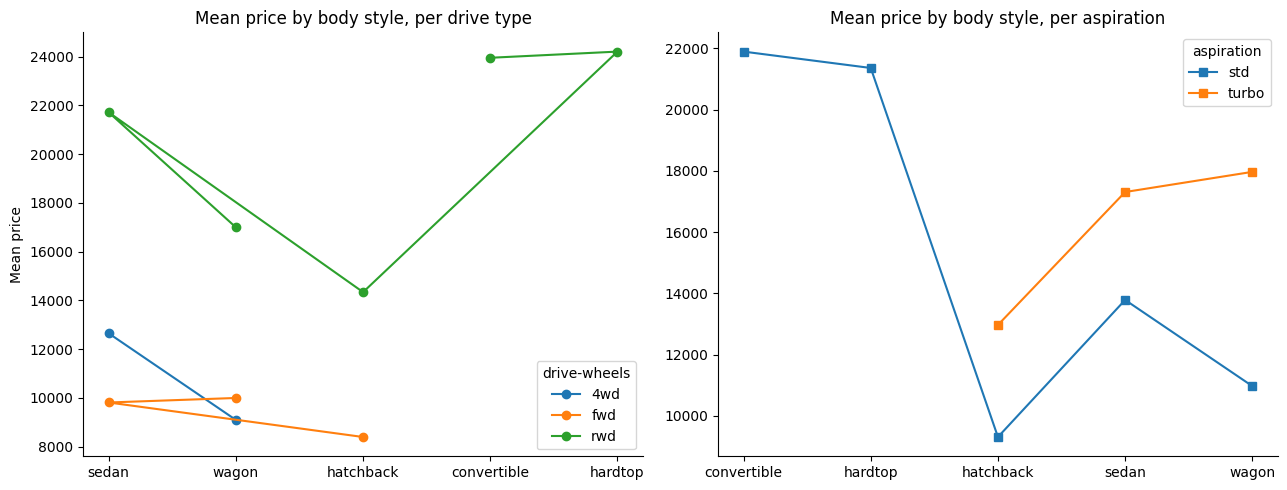

In [ ]:
# Interaction plot

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

for dw, g in df.groupby("drive-wheels"):
    m = g.groupby("body-style")["price"].agg(["mean", "count"])
    m = m[m["count"] >= 3]                      # skip tiny groups
    axs[0].plot(m.index, m["mean"], marker="o", label=dw)
axs[0].set_title("Mean price by body style, per drive type")
axs[0].set_ylabel("Mean price")
axs[0].legend(title="drive-wheels")

for t, g in df.groupby("aspiration"):
    m = g.groupby("body-style")["price"].agg(["mean", "count"])
    m = m[m["count"] >= 3]
    axs[1].plot(m.index, m["mean"], marker="s", label=t)
axs[1].set_title("Mean price by body style, per aspiration")
axs[1].legend(title="aspiration")

plt.tight_layout()
plt.show()

Summary of findings

a) Continuous variables

Engine-size, curb-weight, horsepower, city-L/100km and width have very strong positive links with price (r = 0.75 to 0.87).
Highway-mpg and city-mpg have strong negative links (about -0.70). More efficient cars cost less.
Height, normalized-losses, peak-rpm, stroke and compression-ratio have no real link with price.

b) Categorical variables

Make, number of cylinders, horsepower group and drive wheels have the biggest effects on price (eta² from 0.41 to 0.80).
Fuel-system, engine-type and body-style also have large effects.
Aspiration has a small effect. Fuel type and number of doors have almost no effect.

c) Two categorical variables

Drive wheels is the main driver of price. It explains about 30% of price variation, and body style adds only about 5% on top of it.
None of the three pairs tested has a significant interaction. The two variables add their effects, and neither changes the other’s effect.
Some categorical variables are linked to each other. Body style and number of doors are strongly linked, so do not treat them as independent.kkdd    mmjjgs

Qn 5: Based on your findings, identify the main variables that have the most impact on car price, and support your answer with a feature selection method. Write a short recommendation for a car dealer setting prices.

Main variable that have most impact on car price

Rank	Variable	Combined score	What it means
1	curb-weight	0.93	Heavier cars cost much more.
2	engine-size	0.43	Bigger engines cost more.
3	make (brand)	0.40	Luxury brands carry a price premium.
4	highway-mpg	0.33	Fuel-efficient cars cost less.
5	horsepower	0.29	More power costs more.
6	city-L/100km	0.27	Same story as mpg.
7	width	0.24	Wider cars cost more.
8	fuel-system	0.23	Linked to engine type and power


How this matches the earlier findings
•	Correlation already showed engine-size (0.87), curb-weight (0.83) and horsepower (0.81) as the strongest variables.
•	Drive wheels and number of cylinders also mattered earlier. Feature selection ranked them lower, because their effect is already carried by weight, engine size and horsepower.

Recommendation for a car dealer setting prices
1.	Start with size and power. Use curb-weight, engine size and horsepower as the base for the price. These three explain most of the difference between cheap and expensive cars.
2.	Add a brand premium. Make is the next biggest factor. Jaguar, Mercedes-Benz and Porsche sell at 31,000 to 35,000 on average, while Chevrolet, Dodge and Plymouth sell below 8,000. Do not price two cars of the same size the same if the brands differ.
3.	Adjust for fuel economy. Cars with better highway mpg tend to be cheaper, because they are usually smaller. Use fuel economy as a small adjustment, not as the main driver.
4.	Do not spend effort on features that do not move price. Number of doors, height, stroke, compression ratio, peak rpm and fuel type (gas or diesel) have almost no effect on price in this data.
